In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,Activation,Dropout,Flatten,MaxPooling2D
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import confusion_matrix

I0000 00:00:1795622344.422617    6888 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795622344.706919    6888 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795622346.373542    6888 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
dataset_path = "/home/lokesh/Loki/Projects/GEN AI/Currency_note_reco/Indian Currency Dataset"

In [3]:
X = []
y = []
categories = ["10","20","50","100","200","500","2000"]
for label, category in enumerate(categories):
    folder_path = os.path.join(dataset_path, category)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        try:
            image = keras.utils.load_img( image_path, target_size=(128,128) )
            image = keras.utils.img_to_array(image)
            X.append(image)
            y.append(label)
        except Exception as e:
            print("Skipping:", image_name)

Skipping: .ipynb_checkpoints


In [4]:
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

In [5]:
print(X.shape)
print(y.shape)

(1786, 128, 128, 3)
(1786,)


In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [7]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [8]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1250, 128, 128, 3)
(268, 128, 128, 3)
(1250,)
(268,)


In [9]:
model = Sequential()
model.add(Conv2D(32, (3,3), activation='relu',input_shape=(128,128,3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(7, activation='softmax'))



/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1795622520.870063    6888 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [12]:
history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=15,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/15


W0000 00:00:1795622521.303134    6888 cpu_allocator_impl.cc:174] Allocation of 245760000 exceeds 10% of free system memory.
W0000 00:00:1795622522.565779    8366 cpu_allocator_impl.cc:174] Allocation of 65028096 exceeds 10% of free system memory.
W0000 00:00:1795622522.610281    8366 cpu_allocator_impl.cc:174] Allocation of 30482432 exceeds 10% of free system memory.
W0000 00:00:1795622522.750341    8367 cpu_allocator_impl.cc:174] Allocation of 30482432 exceeds 10% of free system memory.


 1/40 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.0938 - loss: 1.9529

W0000 00:00:1795622522.773871    8365 cpu_allocator_impl.cc:174] Allocation of 25719552 exceeds 10% of free system memory.


40/40 ━━━━━━━━━━━━━━━━━━━━ 15s 343ms/step - accuracy: 0.2472 - loss: 1.8291 - val_accuracy: 0.5112 - val_loss: 1.4519
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 338ms/step - accuracy: 0.4440 - loss: 1.4077 - val_accuracy: 0.4403 - val_loss: 1.3767
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.6800 - loss: 0.9127 - val_accuracy: 0.7761 - val_loss: 0.6314
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.7648 - loss: 0.6751 - val_accuracy: 0.8097 - val_loss: 0.5202
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 350ms/step - accuracy: 0.8008 - loss: 0.5845 - val_accuracy: 0.7388 - val_loss: 0.6293
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.8264 - loss: 0.4715 - val_accuracy: 0.8806 - val_loss: 0.3794
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 335ms/step - accuracy: 0.8512 - loss: 0.3851 - val_accuracy: 0.8694 - val_loss: 0.3507
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 350ms/step - accuracy: 0.8848 - loss: 0.3261 - val_accuracy: 0.880

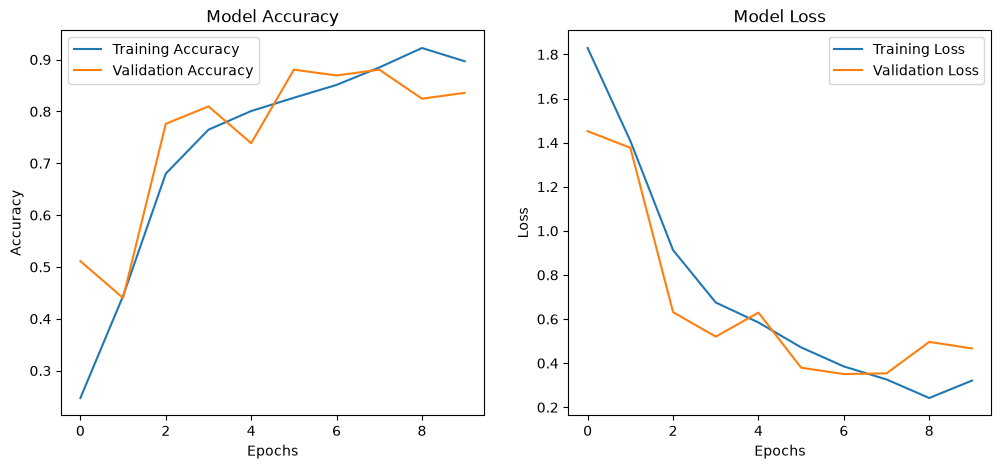

In [13]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [14]:
model.save("currency_note_cnn.keras")

In [15]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.8694 - loss: 0.3507
Test Accuracy: 86.94030046463013 %
Test Loss: 0.35068801045417786


In [16]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

class_names = [
    "10", "20", "50", "100",
    "200", "500", "2000"
]

print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
              precision    recall  f1-score   support

          10       0.97      0.94      0.95        33
          20       0.74      0.94      0.83        49
          50       0.89      0.80      0.85        41
         100       0.81      0.93      0.87        45
         200       0.87      0.42      0.57        31
         500       0.94      1.00      0.97        33
        2000       1.00      0.97      0.99        36

    accuracy                           0.87       268
   macro avg       0.89      0.86      0.86       268
weighted avg       0.88      0.87      0.86       268



<Figure size 1000x800 with 0 Axes>

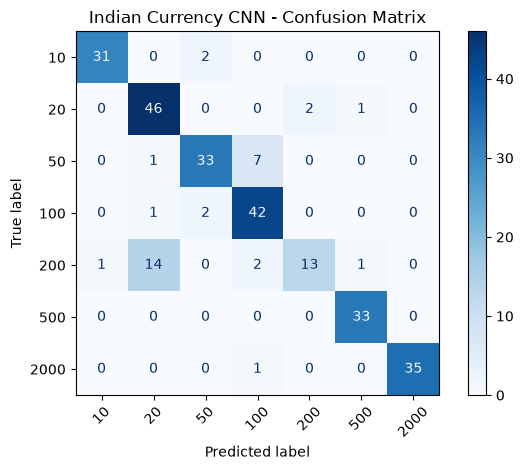

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

class_names = ["10", "20", "50", "100", "200", "500", "2000"]

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Indian Currency CNN - Confusion Matrix")
plt.tight_layout()
plt.show()


In [20]:
app_code = '''
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
from pathlib import Path

st.set_page_config(
    page_title="Indian Currency Recognition",
    page_icon="💵"
)

st.title("💵 Indian Currency Recognition")
st.write("Upload an Indian currency note to identify its denomination.")

MODEL_PATH = Path("currency_note_cnn.keras")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH)

model = load_model()

class_names = ["₹10", "₹20", "₹50", "₹100",
               "₹200", "₹500", "₹2000"]

uploaded_file = st.file_uploader(
    "Upload Currency Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file:

    image = Image.open(uploaded_file).convert("RGB")

    st.image(image, caption="Uploaded Currency",
             use_container_width=True)

    if st.button("Recognize Currency"):

        resized_image = image.resize((128, 128))

        image_array = np.array(
            resized_image,
            dtype=np.float32
        )

        image_array = image_array / 255.0

        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)

        predicted_index = np.argmax(predictions[0])

        predicted_currency = class_names[predicted_index]

        confidence = predictions[0][predicted_index] * 100

        st.success("Recognition Completed!")

        st.metric(
            "Predicted Currency",
            predicted_currency
        )

        st.metric(
            "Confidence",
            f"{confidence:.2f}%"
        )

        st.subheader("Class Probabilities")

        for i, currency in enumerate(class_names):
            st.write(currency)
            st.progress(float(predictions[0][i]))
'''

print("Streamlit application code prepared!")

Streamlit application code prepared!


In [21]:
import subprocess
from pathlib import Path

Path("app.py").write_text(app_code)

process = subprocess.Popen([
    "streamlit",
    "run",
    "app.py",
    "--server.headless=true"
])

print("Streamlit server started!")
print("Open: http://localhost:8501")

Streamlit server started!
Open: http://localhost:8501


2026-11-25 21:49:19.462 Uvicorn server started on :::8501



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://192.168.1.10:8501
  External URL: http://122.167.158.177:8501



I0000 00:00:1795623576.878467    9397 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795623577.030557    9397 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795623578.552990    9397 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1795623580.774059    9397 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

2026-11-25 21:49:50.558 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, 